# Credit Risk Classification: Loan Default Prediction


## Business Understanding

Loan defaults cause significant financial losses for banks and fintech companies.
The goal of this project is to predict whether a loan applicant is likely to default,
so that lenders can make better credit approval decisions.

### Stakeholder
Credit risk team at a bank or fintech company.

### Objective
1. To explore and understand borrower characteristics and patterns associated with loan default.
2. To build and compare multiple classification models for predicting loan default risk.
3. To evaluate model performance using recall and ROC-AUC, prioritizing identification of high-risk borrowers.


### Business Value
- Reduce non-performing loans
- Improve risk management
- Support data-driven lending decisions


In [25]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


df= pd.read_csv(r"C:\Users\bikey\OneDrive\Desktop\Data-science\phase-3-project\data\archive (1).zip")
df.head()
df.shape
df.info()
df.isna().sum()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

## Exploratory Data Analysis (EDA)

This section explores the structure, distribution, and patterns in the dataset
to better understand factors associated with loan default.


Target Varibale Distribution

In [9]:
target = "Default"
y = df[target]


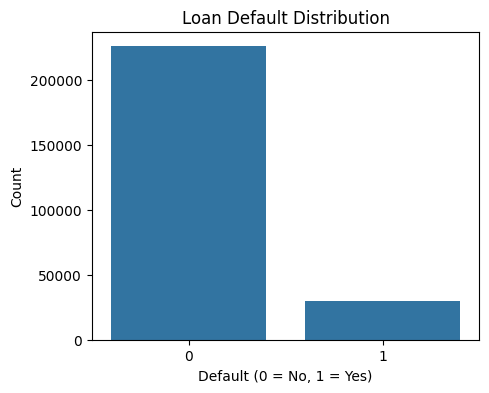

In [10]:
plt.figure(figsize=(5,4))
sns.countplot(x=y)
plt.title("Loan Default Distribution")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()


**Observation:**
The target variable is highly imbalanced, with significantly fewer default cases.
This is typical in credit risk datasets and justifies the use of recall and
class-weighted models during evaluation.


Feature Distributions

In [17]:
numeric_features = df.select_dtypes(include=["int64", "float64"]).columns


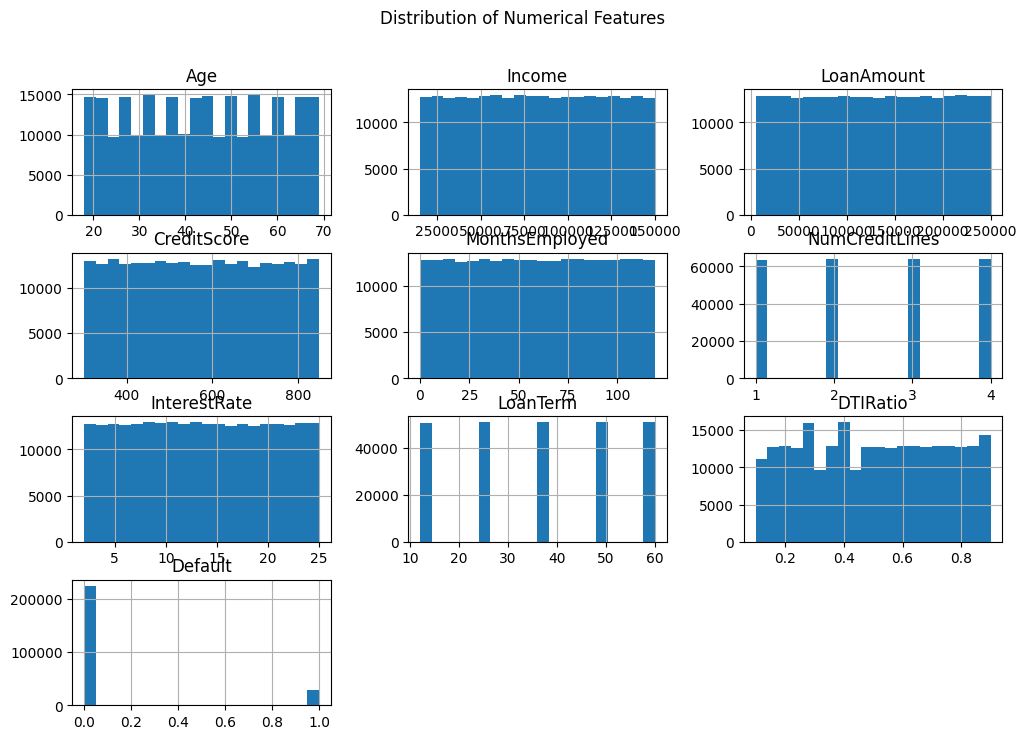

In [18]:
df[numeric_features].hist(figsize=(12, 8), bins=20)
plt.suptitle("Distribution of Numerical Features")
plt.show()


**Observation:**
No extremely high correlations were observed between numerical features,
suggesting a low risk of multicollinearity.


Correlation Analysis

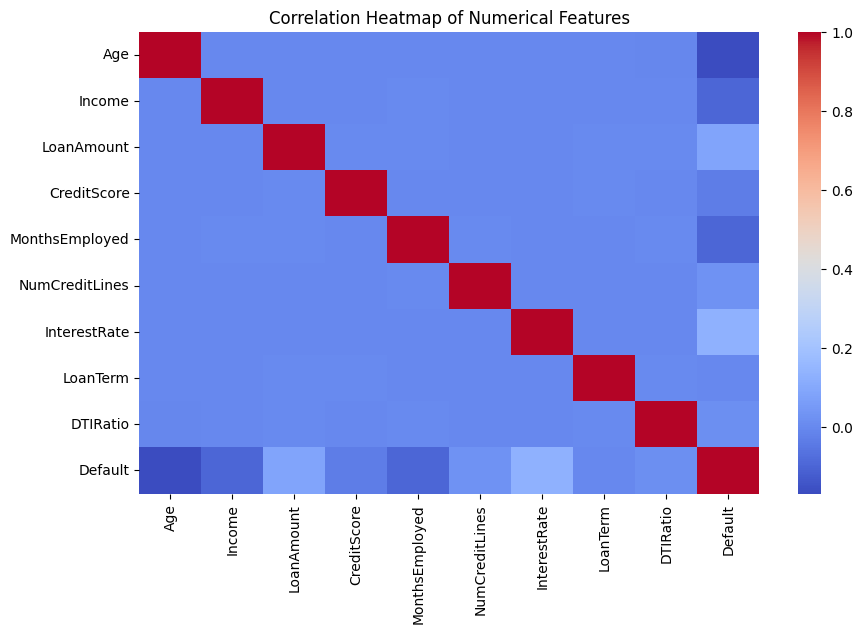

In [19]:
plt.figure(figsize=(10,6))
sns.heatmap(
    df[numeric_features].corr(),
    cmap="coolwarm",
    annot=False
)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()


**Observation:**
No extremely high correlations were observed between numerical features,
suggesting a low risk of multicollinearity.


4. Data Preparation

In [26]:

numeric_transformer = Pipeline(steps=[
("scaler", StandardScaler())
])


categorical_transformer = Pipeline(steps=[
("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer(
transformers=[
("num", numeric_transformer, numeric_features),
("cat", categorical_transformer, categorical_features)
]
)
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.2,
random_state=42,
stratify=y
)

Modeling

Logistic Regression (Baseline)

In [27]:

log_reg = Pipeline(steps=[
("preprocessor", preprocessor),
("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])


log_reg.fit(X_train, y_train)


y_pred_lr = log_reg.predict(X_test)
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.93      0.83      0.88     45139
           1       0.29      0.51      0.37      5931

    accuracy                           0.80     51070
   macro avg       0.61      0.67      0.62     51070
weighted avg       0.85      0.80      0.82     51070



## Decision Tree Model

A Decision Tree classifier was trained to capture non-linear relationships
between borrower characteristics and loan default risk.



              precision    recall  f1-score   support

           0       0.89      1.00      0.94     45139
           1       0.60      0.03      0.06      5931

    accuracy                           0.89     51070
   macro avg       0.74      0.51      0.50     51070
weighted avg       0.85      0.89      0.84     51070



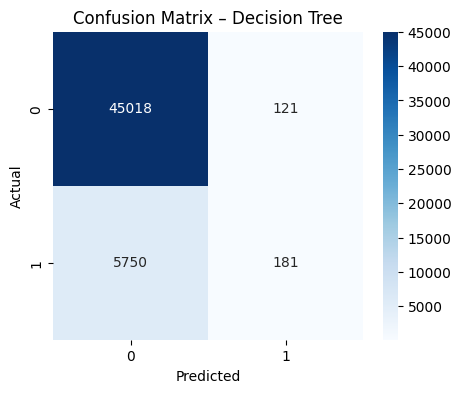

In [29]:

tree = Pipeline(steps=[
("preprocessor", preprocessor),
("model", DecisionTreeClassifier(
max_depth=6,
min_samples_leaf=30,
random_state=42
))
])


tree.fit(X_train, y_train)


y_pred_tree = tree.predict(X_test)
print(classification_report(y_test, y_pred_tree))
cm_tree = confusion_matrix(y_test, y_pred_tree)


plt.figure(figsize=(5,4))
sns.heatmap(cm_tree, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Decision Tree")
plt.show()

Interpretation:
The Decision Tree captures non-linear relationships but shows limited generalization and lower recall for default cases. This makes it less suitable as a final model for credit risk applications.

Random Forest Model

              precision    recall  f1-score   support

           0       0.91      0.56      0.69     45139
           1       0.15      0.58      0.23      5931

    accuracy                           0.56     51070
   macro avg       0.53      0.57      0.46     51070
weighted avg       0.82      0.56      0.64     51070



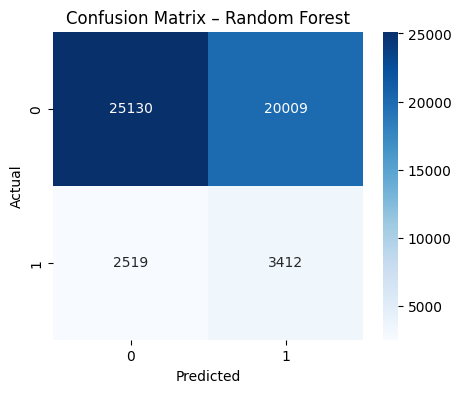

In [30]:

rf = Pipeline(steps=[
("preprocessor", preprocessor),
("model", RandomForestClassifier(
n_estimators=100,
max_depth=10,
min_samples_split=50,
min_samples_leaf=20,
class_weight="balanced",
n_jobs=-1,
random_state=42
))
])


rf.fit(X_train, y_train)


y_pred_rf = rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))
cm_rf = confusion_matrix(y_test, y_pred_rf)


plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Random Forest")
plt.show()


**Model Evaluation**

Because this is a credit risk problem, recall for default cases was prioritized over accuracy. Misclassifying a defaulter as low-risk can result in financial losses.

Random Forest achieved better recall for default cases

ROC-AUC confirms good class separation capability

**Final Model Selection**

Three models were evaluated:

Logistic Regression (baseline)

Decision Tree

Random Forest

The Random Forest model was selected as the final model due to its superior recall and ROC-AUC performance, making it more suitable for credit risk decision support.

**Business Implications**

The final model can be used by credit risk teams to:

Identify high-risk borrowers before loan approval

Reduce non-performing loans

Support risk-based pricing and approval strategies

**Limitations**

The dataset is historical and may not reflect current economic conditions

Informal income sources may not be fully captured

Model predictions should support, not replace, human judgment

**Conclusion**

This project demonstrates how machine learning can support credit risk assessment by predicting loan default risk. By prioritizing recall and using an ensemble approach, the Random Forest model provides actionable insights that support safer and more data-driven lending decisions.